# <span style="color:#1f4e79; font-weight:bold; font-size:30px;">📊 Course Performance Analysis</span>

<img src="images.jpg" width="1000" >

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">🎯 Project Objective</span>

To analyze course engagement and enrollment data to identify popular courses, understand user drop-offs in the enrollment funnel, compare performance across devices, and uncover opportunities to improve course conversion rates using Python.

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">📦 Importing Libraries</span>

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">📂 Data Loading and Initial Overview</span>

In [3]:
df= pd.read_csv('generated_data.csv')

In [11]:
df.head()

,event_id,user_id,course_name,event_name,device
0,E001,U001,Data Analytics,view_course,mobile
1,E002,U001,Data Analytics,enroll_click,mobile
2,E003,U001,Data Analytics,generate_lead,mobile
3,E004,U002,Web Development,view_course,desktop
4,E005,U002,Web Development,enroll_click,desktop


In [12]:
df.shape

(100, 5)

In [13]:
# Data types & structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   event_id     100 non-null    object
 1   user_id      100 non-null    object
 2   course_name  100 non-null    object
 3   event_name   100 non-null    object
 4   device       100 non-null    object
dtypes: object(5)
memory usage: 4.0+ KB


In [14]:
# Summary Statistics
df.describe()

,event_id,user_id,course_name,event_name,device
count,100,100,100,100,100
unique,100,50,3,3,3
top,E001,U027,Web Development,view_course,desktop
freq,1,4,35,55,43


## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">🧹 Data Pre-processing</span>

In [15]:
# Handling missing values
df.isnull().sum()

event_id       0
user_id        0
course_name    0
event_name     0
device         0
dtype: int64

**Observation**

- A null value check was performed across all columns, and *no missing values* were found.
- Therefore, no imputation or row removal was required.

In [16]:
# Removing duplicates
df.duplicated().sum()

0

**Observation**

- Duplicate records were checked across the dataset, and *no duplicate rows* were identified. 

In [17]:
df.dtypes

event_id       object
user_id        object
course_name    object
event_name     object
device         object
dtype: object

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">📊 Exploratory Data Analysis (EDA) and Visualizations</span>

### <span style="color:#2e75b6; font-weight:bold;">Course Performance Analysis</span>

#### <span style="color:#2e75b6; font-weight:bold;">Total Course Views by Course Name</span>

In [24]:
# To identify which course got highest views
course_views = (
    df[df['event_name'] == 'view_course']
    .groupby('course_name')
    .size()
    .reset_index(name='total_views')
    .sort_values('total_views', ascending=False)
)

course_views

,course_name,total_views
2,Web Development,19
0,Cyber Security,18
1,Data Analytics,18


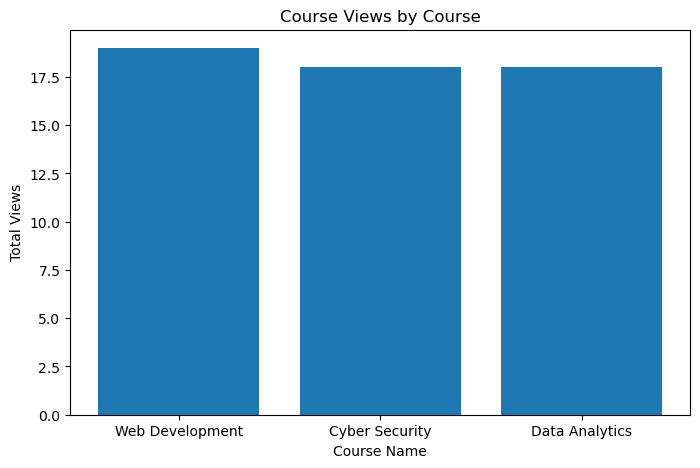

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(course_views['course_name'], course_views['total_views'])
plt.title('Course Views by Course')
plt.xlabel('Course Name')
plt.ylabel('Total Views')
plt.show()

**Observation**

- Web Development received the highest number of course views (19), while Cyber Security and Data Analytics each recorded 18 views, indicating nearly equal interest across all three courses.

#### <span style="color:#2e75b6; font-weight:bold;">Total Enrollments by Course Name</span>

In [22]:
# To identify which course got highest enrollment clicks
course_enrollments = (
    df[df['event_name'] == 'enroll_click']
    .groupby('course_name')
    .size()
    .reset_index(name='total_enroll_clicks')
    .sort_values('total_enroll_clicks', ascending=False)
)

course_enrollments

,course_name,total_enroll_clicks
1,Data Analytics,12
2,Web Development,12
0,Cyber Security,11


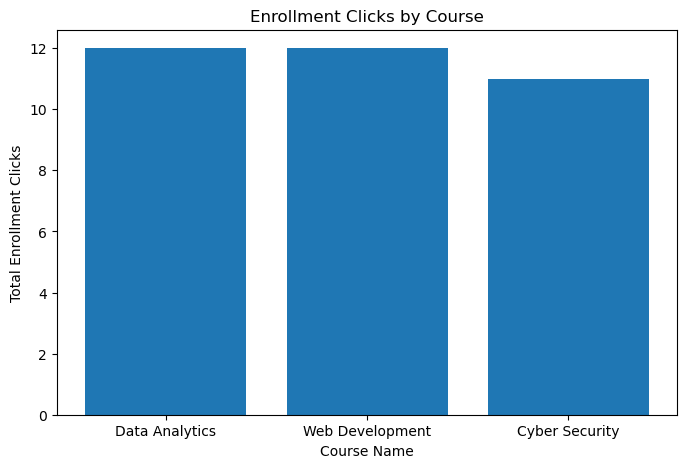

In [25]:
plt.figure(figsize=(8, 5))

plt.bar(course_enrollments['course_name'],
        course_enrollments['total_enroll_clicks'])

plt.title('Enrollment Clicks by Course')
plt.xlabel('Course Name')
plt.ylabel('Total Enrollment Clicks')
plt.show()

**Observation**

- Data Analytics and Web Development recorded the highest number of enrollment clicks, with 12 each, while Cyber Security recorded 11
- Enrollment interest was nearly equal across all three courses.

### <span style="color:#2e75b6; font-weight:bold;">Course Conversion Rate</span>

In [27]:
# To identify how many people who viewed the course actually enrolled for the course successfully
course_conversion = df.pivot_table(
    index='course_name',
    columns='event_name',
    values='user_id',
    aggfunc='nunique',
    fill_value=0
).reset_index()

course_conversion['conversion_rate'] = (course_conversion['generate_lead']/ course_conversion['view_course'] * 100).round(2)

course_conversion

event_name,course_name,enroll_click,generate_lead,view_course,conversion_rate
0,Cyber Security,11,2,16,12.50
1,Data Analytics,12,4,17,23.53
2,Web Development,12,4,17,23.53


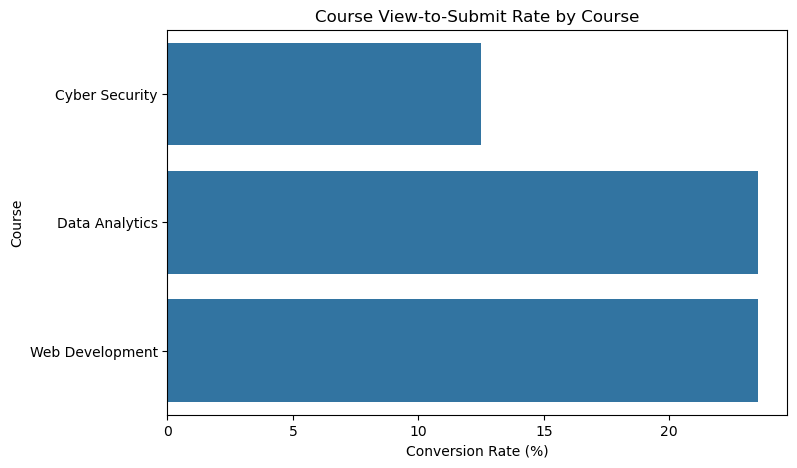

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=course_conversion,
    x='conversion_rate',
    y='course_name'
)

plt.title('Course View-to-Submit Rate by Course')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Course')
plt.show()

**Observation**

- Data Analytics and Web Development achieved the highest view-to-submit conversion rates at 23.53% each.
- Cyber Security recorded the lowest at 12.50%, indicating an opportunity to investigate its course enrollment journey.

### <span style="color:#2e75b6; font-weight:bold;">Enrollment Funnel Analysis</span>

In [4]:
# To identify at which stage do users drop off during the course enrollment journey
funnel_data = (df.groupby('event_name')['user_id'].nunique().reset_index())
funnel_data.columns = ['event_name', 'unique_users']
funnel_data

,event_name,unique_users
0,enroll_click,35
1,generate_lead,10
2,view_course,50


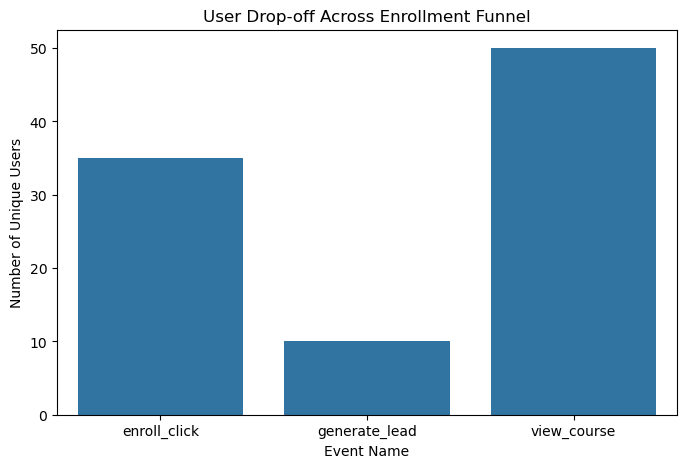

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=funnel_data,
    y='unique_users',
    x='event_name'
)

plt.title('User Drop-off Across Enrollment Funnel')
plt.ylabel('Number of Unique Users')
plt.xlabel('Event Name')
plt.show()

**Observation**

- Unique users decreased from 50 who viewed courses to 35 who clicked enroll, and only 10 generated leads.
- The largest drop occurred between course views and enrollment clicks, suggesting an opportunity to improve engagement and encourage enrollment.

### <span style="color:#2e75b6; font-weight:bold;">Device Performance Analysis</span>

In [7]:
# To identify the user behaviour changes across different devices
device_performance = df.groupby(['device', 'event_name']).size().unstack(fill_value=0)

device_performance

event_name,enroll_click,generate_lead,view_course
device,,,
desktop,17,6,20
mobile,12,4,22
tablet,6,0,13


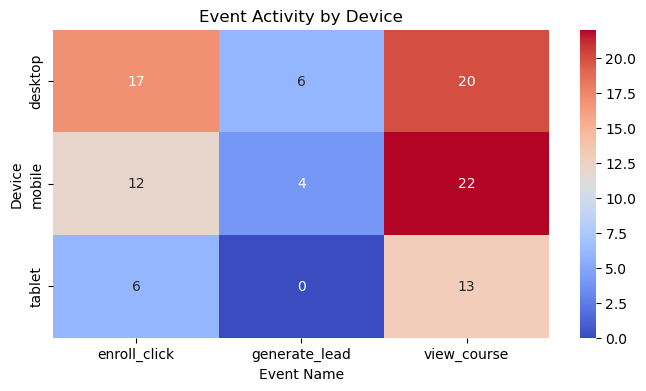

In [9]:
plt.figure(figsize=(8, 4))

sns.heatmap(device_performance, annot=True, cmap='coolwarm')

plt.title('Event Activity by Device')
plt.xlabel('Event Name')
plt.ylabel('Device')
plt.show()

**Observation**

- Desktop recorded the highest number of enrollment clicks (17) and submissions (6), while tablet recorded 6 enrollment clicks but no leads.
- Investigate the tablet enrollment experience further.

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">📝 Insight Generation and Recommendations</span>

### <span style="color:#2e75b6; font-weight:bold;">🔍 Key Insights</span>

- **Course Engagement**: Web Development received the highest number of course views (19), while Data Analytics and Web Development recorded the highest enrollment clicks (12 each).
- **Course Conversion**: Data Analytics and Web Development achieved the highest view-to-lead conversion rates at 23.53% each, compared with 12.50% for Cyber Security.
- **Enrollment Funnel**: Of the 50 unique users who viewed courses, 35 clicked enroll and 10 generated leads. The largest drop occurred between course views and enrollment clicks.
- **Device Performance**: Desktop recorded the highest enrollment clicks (17) and form submissions (6), while tablet recorded 6 enrollment clicks but no enrollments.

### <span style="color:#2e75b6; font-weight:bold;">🚀 Actionable Recommendations</span>

- **Improve Course Information and Pricing**: Review how course fees and durations are displayed, compare pricing and course offerings with competing institutes, and assess whether the fees provide good value. If pricing appears to be a barrier, consider testing discounts or flexible payment options to improve enrollment.
- **Optimize Cyber Security Conversion**: Investigate the Cyber Security course page and enrollment process to identify potential barriers to successfull enrollments.
- **Review Tablet Experience**: Test the enrollment form and course pages on tablet devices to check for any usability issues.
- **Monitor Funnel Drop-offs**: Track each stage of the enrollment journey to identify where users leave and evaluate improvements over time.

### <span style="color:#2e75b6; font-weight:bold;">⚠️ Limitations</span>

This analysis uses synthetic data created for demonstration purposes. The findings illustrate how analytics can support decision-making but should not be treated as actual business performance. Continue monitoring actual GA4 events to validate these findings and make more reliable business decisions.

## <span style="color:#1f4e79; font-weight:bold; font-size:20px;">✅  Conclusion</span>

This project demonstrated how Python can be used to analyze course engagement, compare conversion rates, examine enrollment funnel drop-offs, and evaluate device-level activity. Visualizations helped identify differences in course performance and areas for further investigation. 